# Part 2 - UWB Anchor Global Localization (GDOP & Incorrect Anchor Placement)

This notebook explores UWB-based robot localization with:

- Geometric Dilution of Precision (GDOP) analysis
- UWB anchor placement evaluation
- Anchor mis-calibration effects on pose estimation

In [1]:
# Imports
import sys
sys.path.insert(0, '../src')
from part2_functions import run_gdop_analysis, plot_robot_with_anchors, analyze_anchor_miscalibration
from config import TrajectoryConfig, UWBNoiseConfig
import numpy as np

duration = 50.0
timestep = 0.1

## UWB Anchor localization Analysis
Play around with the uncertainty on the measured UWB distance sigma_uwb to see how it affects the localization accuracy.
How is the error affected by the error on the measured distance between the robot and the anchors?
What happens when you play with the anchor positions? Try to place them in a line, or very close to each other. How is the localization accuracy affected?

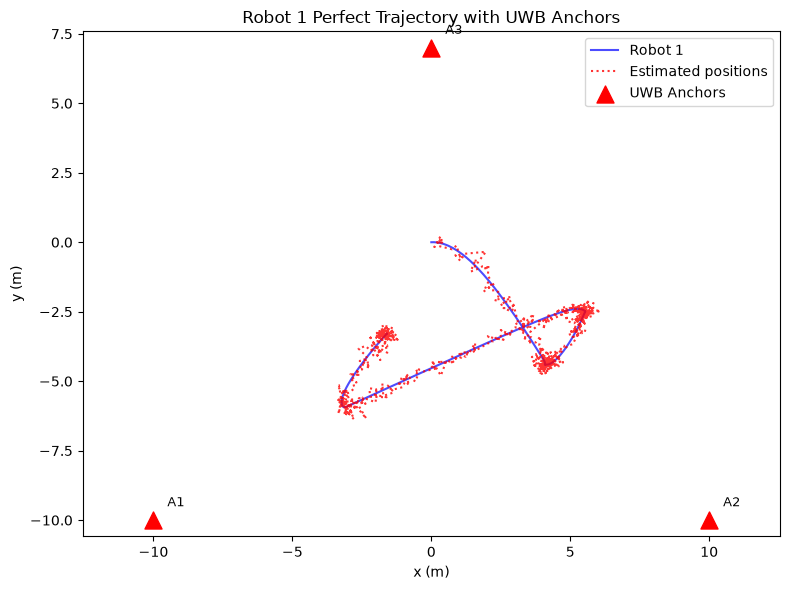

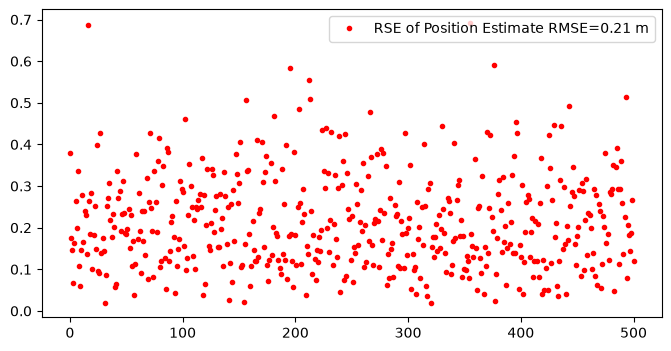

In [2]:
# Parameters
sigma_uwb = 0.2
anchor_positions = np.array([
    [-10, -10.0],
    [10.0, -10.0],
    [0.0, 7]
])

# Trajectory config
traj_config = TrajectoryConfig(duration=duration, timestep=timestep, seed=42)
# UWB noise parameters
uwb_noise_config = UWBNoiseConfig(sig_range=sigma_uwb)  # 20 cm range noise
# Visualize robot trajectory with anchors
poses_robot1 = plot_robot_with_anchors(traj_config, uwb_noise_config, anchor_positions)

## Geometric Dilution of Precision (GDOP) Analysis
Play around with the anchor positions to see how it affects the GDOP and localization accuracy.
What happens when you place all anchors on a line? How does it affect the GDOP and localization accuracy?
What happens when you place all anchors close to each other?

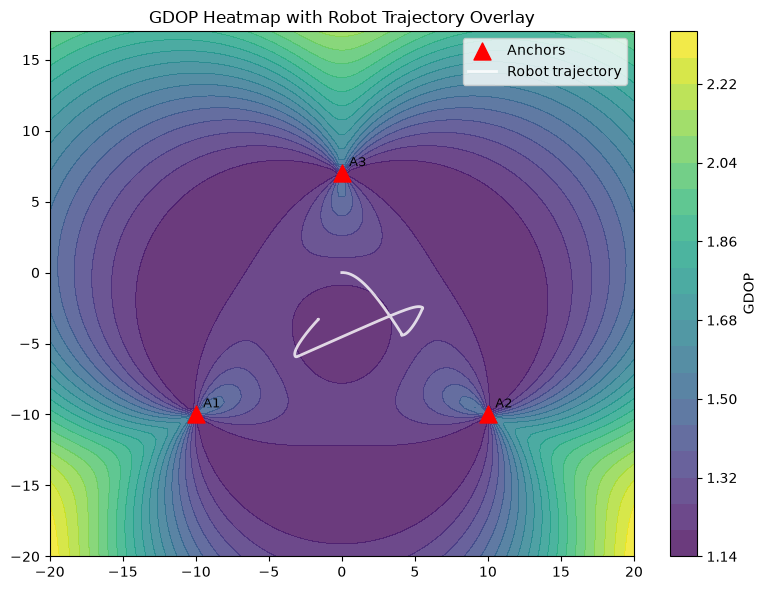

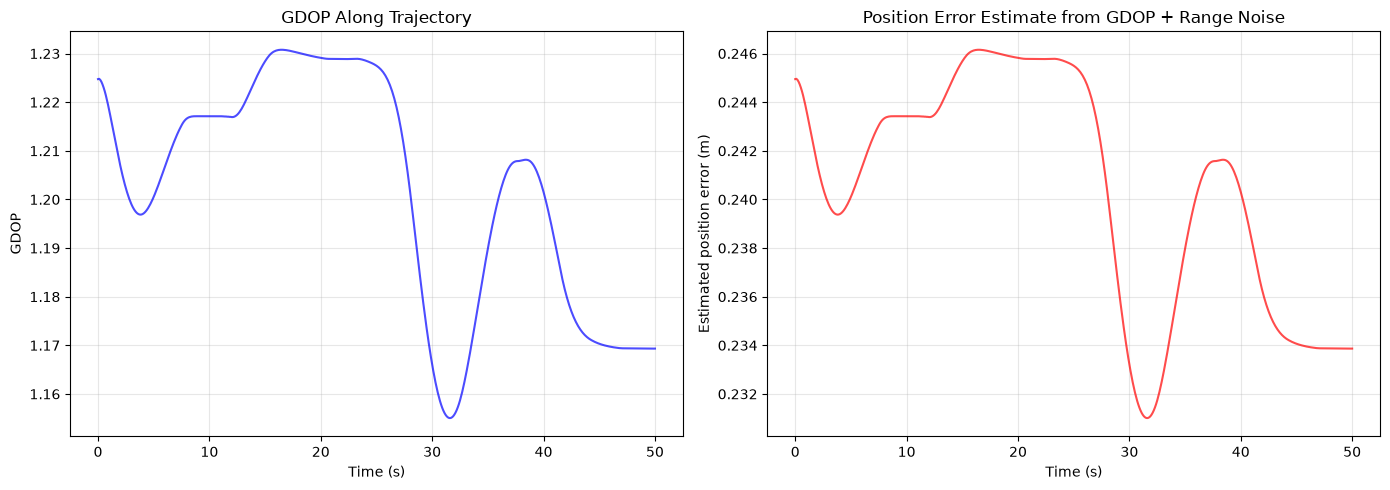

In [3]:
# Parameters
sigma_uwb = 0.2
anchor_positions = np.array([
    [-10, -10.0],
    [10.0, -10.0],
    [0.0, 7]
])

# Trajectory config
traj_config = TrajectoryConfig(duration=duration, timestep=timestep, seed=42)
# UWB noise parameters
uwb_noise_config = UWBNoiseConfig(sig_range=sigma_uwb)  # 20 cm range noise
run_gdop_analysis(
    traj_config,
    anchor_positions,
    uwb_noise_config)

## Anchor Mis-calibration Analysis
Play around with the uncertainty on the position of the anchor locations (sigma_uwb_anchor) and investigate the effects on the error.

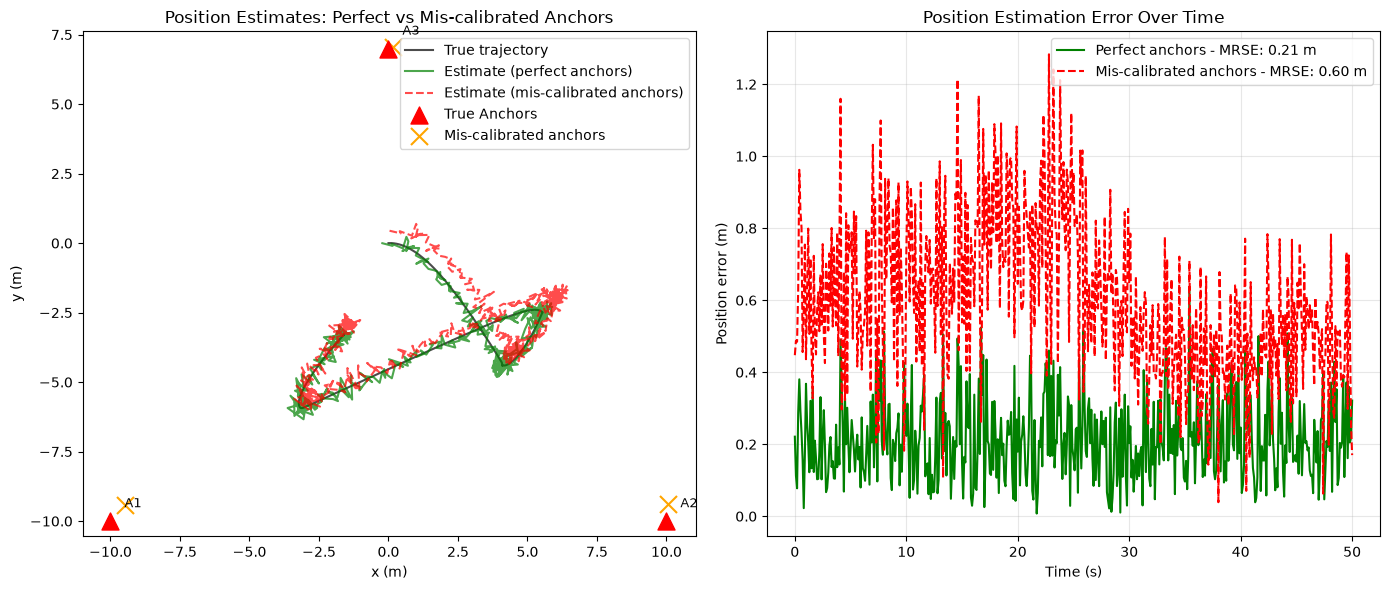

In [4]:
# Analyze anchor mis-calibration
sigma_uwb_anchor = 1
sigma_uwb = 0.2
anchor_positions = np.array([
    [-10, -10.0],
    [10.0, -10.0],
    [0.0, 7]
])

uwb_noise_config = UWBNoiseConfig(sig_range=sigma_uwb)  # 20 cm range noise
traj_config = TrajectoryConfig(duration=duration, timestep=timestep, seed=42)
# Run miscalibration analysis
analyze_anchor_miscalibration(
    traj_config,
    anchor_positions,
    uwb_noise_config,
    sigma_uwb_anchor
)